# Global Economic Data Analysis & Forecasting

**Economic Data Analysis | Machine Learning | GDP Growth Prediction**

## Project Overview

This project explores annual GDP growth, consumer-price inflation and unemployment in 20 countries over 1990–2025. It covers exploratory analysis, data-quality checks, feature engineering, model comparison and experimental GDP growth estimates for 2026.

**Methods:** Pandas and NumPy for data preparation, Matplotlib and Seaborn for visualization, Scikit-learn for regression and validation, and Streamlit with Plotly for the dashboard.

## نظرة عامة

تحليل مؤشرات النمو الاقتصادي والتضخم والبطالة في 20 دولة خلال 1990–2025، مع مقارنة نماذج التعلّم الآلي وتجهيز تقديرات تجريبية لنمو 2026.

يحتوي الدفتر على خطوات **Data Import, Cleaning, EDA, Feature Engineering, Model Evaluation, Forecasting** مع شرح موجز لكل مرحلة.

**Data source:** World Bank indicator CSV in `data/raw/` (not bundled with the notebook). The original file is required to rerun the analysis from the beginning.


---

## 01 · Data Import & Inspection

قراءة الملف الخام، فهم الأعمدة، ومراجعة النواقص قبل أي تحليل.

### Environment Setup — Import Libraries

تحميل مكتبات معالجة البيانات والرسم البياني المستخدمة في مراحل المشروع.

In [ ]:
# Environment Setup — Libraries and Project Paths
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Works when the Notebook is launched from the repository root or notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
DATA_DIR.mkdir(parents=True, exist_ok=True)
print('Project folder:', PROJECT_ROOT)


### Data Extraction — Load World Bank CSV

قراءة ملف البيانات الأصلي بصيغة CSV وتجاوز صفوف الوصف السابقة لرؤوس الأعمدة.

In [ ]:
# Data Import — World Bank CSV
# Read the untouched source file and verify the required columns.
raw_name = 'API_Download_DS2_EN_csv_v2_146823_LIST.csv'
raw_candidates = [PROJECT_ROOT / 'data' / 'raw' / raw_name, PROJECT_ROOT / raw_name]
raw_file = next((path for path in raw_candidates if path.exists()), None)
if raw_file is None:
    raise FileNotFoundError(
        f"Required source CSV was not found. Put {raw_name} in "
        f"{PROJECT_ROOT / 'data' / 'raw'}"
    )

df = pd.read_csv(raw_file, skiprows=4)
required_columns = {'Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', 'Year', 'Value'}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f'Missing source columns: {sorted(missing_columns)}')
print(f'Loaded {len(df):,} records from {raw_file.name}')


### Data Preview — First Records

معاينة أول صفوف البيانات والتأكد من نجاح القراءة.

In [3]:
# Data Preview — First Records
print(df.head())


           Country Name Country Code         Indicator Name  \
0  United Arab Emirates          ARE  GDP growth (annual %)   
1  United Arab Emirates          ARE  GDP growth (annual %)   
2  United Arab Emirates          ARE  GDP growth (annual %)   
3  United Arab Emirates          ARE  GDP growth (annual %)   
4  United Arab Emirates          ARE  GDP growth (annual %)   

      Indicator Code  Year      Value  Unnamed: 6  
0  NY.GDP.MKTP.KD.ZG  1990  18.327723         NaN  
1  NY.GDP.MKTP.KD.ZG  1991   0.860104         NaN  
2  NY.GDP.MKTP.KD.ZG  1992   3.345282         NaN  
3  NY.GDP.MKTP.KD.ZG  1993   1.261098         NaN  
4  NY.GDP.MKTP.KD.ZG  1994   6.896076         NaN  


### Data Preview — Latest Records

فحص آخر صفوف الملف لرؤية آخر السجلات المتاحة.

In [4]:
# Data Preview — Latest Records
print(df.tail())


      Country Name Country Code     Indicator Name Indicator Code  Year  \
3595  South Africa          ZAF  Population, total    SP.POP.TOTL  2021   
3596  South Africa          ZAF  Population, total    SP.POP.TOTL  2022   
3597  South Africa          ZAF  Population, total    SP.POP.TOTL  2023   
3598  South Africa          ZAF  Population, total    SP.POP.TOTL  2024   
3599  South Africa          ZAF  Population, total    SP.POP.TOTL  2025   

           Value  Unnamed: 6  
3595  61502603.0         NaN  
3596  62378410.0         NaN  
3597  63212384.0         NaN  
3598  64007187.0         NaN  
3599  64747319.0         NaN  


### Schema Inspection — Column Names

عرض أسماء الأعمدة الأساسية وتحديد الأعمدة غير اللازمة.

In [5]:
# Schema Inspection — Column Names
print(df.columns)


Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       'Year', 'Value', 'Unnamed: 6'],
      dtype='str')


### Dataset Overview — Types & Memory

مراجعة أنواع البيانات والقيم غير الفارغة واستهلاك الذاكرة.

In [6]:
# Dataset Overview — Types & Memory
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    3600 non-null   str    
 1   Country Code    3600 non-null   str    
 2   Indicator Name  3600 non-null   str    
 3   Indicator Code  3600 non-null   str    
 4   Year            3600 non-null   int64  
 5   Value           3559 non-null   float64
 6   Unnamed: 6      0 non-null      float64
dtypes: float64(2), int64(1), str(4)
memory usage: 400.0 KB


### Missing Value Standardization

تحويل الرموز النصية الدالة على النقص إلى قيم `NaN` حقيقية ثم حساب القيم المفقودة.

In [7]:
# Missing Value Standardization
#  يشوف الناقص ويعرفنا فين 

df.replace(
    r'(?i)^\s*(\?|n/?a|null|none|nan|missing|unknown|not available|-)?\s*$',
    np.nan,
    regex=True,
    inplace=True
)

print(df.isnull().sum())


Country Name         0
Country Code         0
Indicator Name       0
Indicator Code       0
Year                 0
Value               41
Unnamed: 6        3600
dtype: int64


### Data Cardinality — Unique Values

قياس عدد القيم المختلفة في كل عمود لاكتشاف تنوع الدول والسنوات والمؤشرات.

In [8]:
# Data Cardinality — Unique Values
print(df.nunique())


Country Name        20
Country Code        20
Indicator Name       5
Indicator Code       5
Year                36
Value             3535
Unnamed: 6           0
dtype: int64


### Data Profiling — Country & Indicator Values

استعراض الدول ورموزها والمؤشرات والسنوات والقيم المتاحة للتحقق من محتوى الملف.

In [9]:
# Data Profiling — Country & Indicator Values
for column in ['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', 'Year']:
    print(f"\n{column}: {df[column].dropna().unique()}")
print("\nValue sample:", df['Value'].dropna().head(10).tolist())



Country Name: <ArrowStringArray>
['United Arab Emirates',            'Australia',               'Brazil',
               'Canada',                'China',              'Germany',
     'Egypt, Arab Rep.',                'Spain',               'France',
       'United Kingdom',            'Indonesia',                'India',
                'Italy',                'Japan',          'Korea, Rep.',
               'Mexico',         'Saudi Arabia',              'Turkiye',
        'United States',         'South Africa']
Length: 20, dtype: str

Country Code: <ArrowStringArray>
['ARE', 'AUS', 'BRA', 'CAN', 'CHN', 'DEU', 'EGY', 'ESP', 'FRA', 'GBR', 'IDN',
 'IND', 'ITA', 'JPN', 'KOR', 'MEX', 'SAU', 'TUR', 'USA', 'ZAF']
Length: 20, dtype: str

Indicator Name: <ArrowStringArray>
[                                              'GDP growth (annual %)',
                               'Inflation, consumer prices (annual %)',
 'Unemployment, total (% of total labor force) (modeled ILO estimate)',
     

---

## 02 · Data Cleaning & Quality Checks

تنظيف البيانات وتوثيق السجلات المتاحة والناقصة دون اختراع قيم.

### Column Cleaning — Remove Unnamed Field

إزالة العمود الفارغ الناتج عن تصدير CSV، بدون خطأ لو العمود مش موجود.

In [10]:
# Column Cleaning — Remove Unnamed Field
# Drop the empty CSV export column only if it exists.
df = df.drop(columns=['Unnamed: 6'], errors='ignore')

# Ensure that numerical statistics operate on numeric data.
df['Year'] = pd.to_numeric(df['Year'], errors='raise').astype(int)
df['Value'] = pd.to_numeric(df['Value'], errors='coerce')


### Schema Verification — After Cleanup

التأكد من أسماء الأعمدة بعد حذف العمود الزائد.

In [11]:
# Schema Verification — After Cleanup
print(df.columns)


Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       'Year', 'Value'],
      dtype='str')


### Missingness Review — GDP Indicator Values

استعراض توزيع القيم والـ`NaN` في عمود `Value`.

In [12]:
# Missingness Review — GDP Indicator Values
for col in ["Value"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))



Value
Value
NaN             41
4.550000e+00     3
5.600000e+00     3
3.120000e+00     2
8.509000e+00     2
                ..
6.150260e+07     1
6.237841e+07     1
6.321238e+07     1
6.400719e+07     1
6.474732e+07     1
Name: count, Length: 3536, dtype: int64


### Missing Data Audit — Find Incomplete Records

استخراج الصفوف التي تفتقد قيمة اقتصادية مع الدولة والمؤشر والسنة.

In [13]:
# Missing Data Audit — Find Incomplete Records
missing = df[df['Value'].isna()]

missing[['Country Name', 'Indicator Name', 'Year']]


,Country Name,Indicator Name,Year
35,United Arab Emirates,GDP growth (annual %),2025
36,United Arab Emirates,"Inflation, consumer prices (annual %)",1990
37,United Arab Emirates,"Inflation, consumer prices (annual %)",1991
38,United Arab Emirates,"Inflation, consumer prices (annual %)",1992
39,United Arab Emirates,"Inflation, consumer prices (annual %)",1993
40,United Arab Emirates,"Inflation, consumer prices (annual %)",1994
41,United Arab Emirates,"Inflation, consumer prices (annual %)",1995
42,United Arab Emirates,"Inflation, consumer prices (annual %)",1996
43,United Arab Emirates,"Inflation, consumer prices (annual %)",1997
44,United Arab Emirates,"Inflation, consumer prices (annual %)",1998


### Missing Data Audit — By Indicator

حساب عدد القيم الناقصة لكل مؤشر اقتصادي.

In [14]:
# Missing Data Audit — By Indicator
missing.groupby('Indicator Name').size()


Indicator Name
GDP (current US$)                                                       1
GDP growth (annual %)                                                   1
Inflation, consumer prices (annual %)                                  19
Unemployment, total (% of total labor force) (modeled ILO estimate)    20
dtype: int64

### Missing Data Audit — By Year

تحديد السنوات الأكثر نقصًا في البيانات.

In [15]:
# Missing Data Audit — By Year
missing.groupby('Year').size().sort_index()


Year
1990    21
1991     1
1992     1
1993     1
1994     1
1995     1
1996     1
1997     1
1998     1
1999     1
2000     1
2001     1
2002     1
2003     1
2004     1
2005     1
2006     1
2007     1
2025     3
dtype: int64

### Missing Data Audit — Country & Indicator

تحديد نطاق السنوات الناقصة لكل دولة ومؤشر.

In [16]:
# Missing Data Audit — Country & Indicator
missing.groupby(
    ['Country Name', 'Indicator Name']
)['Year'].agg(['count', 'min', 'max'])


,,count,min,max
Country Name,Indicator Name,,,
Australia,"Unemployment, total (% of total labor force) (modeled ILO estimate)",1,1990,1990
Brazil,"Unemployment, total (% of total labor force) (modeled ILO estimate)",1,1990,1990
Canada,"Unemployment, total (% of total labor force) (modeled ILO estimate)",1,1990,1990
China,"Unemployment, total (% of total labor force) (modeled ILO estimate)",1,1990,1990
"Egypt, Arab Rep.","Unemployment, total (% of total labor force) (modeled ILO estimate)",1,1990,1990
France,"Unemployment, total (% of total labor force) (modeled ILO estimate)",1,1990,1990
Germany,"Unemployment, total (% of total labor force) (modeled ILO estimate)",1,1990,1990
India,"Unemployment, total (% of total labor force) (modeled ILO estimate)",1,1990,1990
Indonesia,"Unemployment, total (% of total labor force) (modeled ILO estimate)",1,1990,1990


### Recent Data Quality — Missing Values in 2025

مراجعة القيم المفقودة في أحدث سنة داخل الـDataset.

In [17]:
# Recent Data Quality — Missing Values in 2025
missing[missing['Year'] == 2025]


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
35,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,2025,NaN
143,United Arab Emirates,ARE,GDP (current US$),NY.GDP.MKTP.CD,2025,NaN
3311,United States,USA,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,2025,NaN


### Create Clean Dataset — Working Copy

إنشاء نسخة مستقلة `df_clean` للحفاظ على البيانات السابقة.

In [18]:
# Create Clean Dataset — Working Copy
import numpy as np

df_clean = df.copy()


### Data Quality Flag — Availability Status

إنشاء عمود `Data_Status` لتمييز السجلات المتاحة عن الناقصة.

In [19]:
# Data Quality Flag — Availability Status
df_clean['Data_Status'] = np.where(
    df_clean['Value'].isna(),
    'Missing',
    'Available'
)


### Data Completeness — Status Summary

حساب عدد السجلات المتاحة والناقصة.

In [20]:
# Data Completeness — Status Summary
df_clean['Data_Status'].value_counts()


Data_Status
Available    3559
Missing        41
Name: count, dtype: int64

### Inspect Missing Records

عرض جميع الصفوف التي تم تصنيفها `Missing`.

In [21]:
# Inspect Missing Records
df_clean[df_clean['Data_Status'] == 'Missing']


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value,Data_Status
35,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,2025,NaN,Missing
36,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1990,NaN,Missing
37,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1991,NaN,Missing
38,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1992,NaN,Missing
39,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1993,NaN,Missing
40,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1994,NaN,Missing
41,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1995,NaN,Missing
42,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1996,NaN,Missing
43,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1997,NaN,Missing
44,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1998,NaN,Missing


### Country Quality Check — Egypt

فحص السجلات المتاحة لمصر بعد التنظيف.

In [22]:
# Country Quality Check — Egypt
df_clean[
    (df_clean['Data_Status'] == 'Available') &
    (df_clean['Country Name'] == 'Egypt, Arab Rep.')
]


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value,Data_Status
1080,"Egypt, Arab Rep.",EGY,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1990,5.667029e+00,Available
1081,"Egypt, Arab Rep.",EGY,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1991,1.125405e+00,Available
1082,"Egypt, Arab Rep.",EGY,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1992,4.472859e+00,Available
1083,"Egypt, Arab Rep.",EGY,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1993,2.900791e+00,Available
1084,"Egypt, Arab Rep.",EGY,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1994,3.973172e+00,Available
...,...,...,...,...,...,...,...
1255,"Egypt, Arab Rep.",EGY,"Population, total",SP.POP.TOTL,2021,1.109570e+08,Available
1256,"Egypt, Arab Rep.",EGY,"Population, total",SP.POP.TOTL,2022,1.126182e+08,Available
1257,"Egypt, Arab Rep.",EGY,"Population, total",SP.POP.TOTL,2023,1.145358e+08,Available
1258,"Egypt, Arab Rep.",EGY,"Population, total",SP.POP.TOTL,2024,1.165383e+08,Available


### Filter — Available Observations

عرض السجلات المكتملة فقط لأغراض الاستكشاف.

In [23]:
# Filter — Available Observations
df_clean[df_clean['Data_Status'] == 'Available']


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value,Data_Status
0,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1990,1.832772e+01,Available
1,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1991,8.601043e-01,Available
2,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1992,3.345282e+00,Available
3,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1993,1.261098e+00,Available
4,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1994,6.896076e+00,Available
...,...,...,...,...,...,...,...
3595,South Africa,ZAF,"Population, total",SP.POP.TOTL,2021,6.150260e+07,Available
3596,South Africa,ZAF,"Population, total",SP.POP.TOTL,2022,6.237841e+07,Available
3597,South Africa,ZAF,"Population, total",SP.POP.TOTL,2023,6.321238e+07,Available
3598,South Africa,ZAF,"Population, total",SP.POP.TOTL,2024,6.400719e+07,Available


### Completeness Ranking — Countries

ترتيب الدول حسب عدد السجلات الاقتصادية المتاحة.

In [24]:
# Completeness Ranking — Countries
available_by_country = (
    df_clean[df_clean['Data_Status'] == 'Available']
    .groupby('Country Name')
    .size()
    .sort_values(ascending=False)
)

available_by_country


Country Name
Australia               179
Brazil                  179
United Kingdom          179
Turkiye                 179
Spain                   179
South Africa            179
Saudi Arabia            179
Mexico                  179
Korea, Rep.             179
Japan                   179
Italy                   179
Indonesia               179
India                   179
Germany                 179
France                  179
Egypt, Arab Rep.        179
China                   179
Canada                  179
United States           178
United Arab Emirates    159
dtype: int64

---

## 03 · GDP Growth — Exploratory Analysis

مقارنة الاقتصادات، دراسة الاتجاهات التاريخية وفترات الانكماش.

### GDP Growth Dataset — Indicator Selection

تصفية مؤشر النمو الاقتصادي السنوي GDP Growth من البيانات الطويلة.

In [25]:
# GDP Growth Dataset — Indicator Selection
gdp_growth = df_clean[
    df_clean['Indicator Code'] == 'NY.GDP.MKTP.KD.ZG'
]


### GDP Growth — Quick Preview

فحص أول السجلات الخاصة بالنمو الاقتصادي.

In [26]:
# GDP Growth — Quick Preview
gdp_growth.head()


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value,Data_Status
0,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1990,18.327723,Available
1,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1991,0.860104,Available
2,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1992,3.345282,Available
3,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1993,1.261098,Available
4,United Arab Emirates,ARE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1994,6.896076,Available


### GDP Growth — Historical Country Averages

حساب متوسط النمو السنوي التاريخي لكل دولة وترتيبها.

In [27]:
# GDP Growth — Historical Country Averages
average_growth = (
    gdp_growth
    .groupby('Country Name')['Value']
    .mean()
    .sort_values(ascending=False)
)

average_growth


Country Name
China                   8.619410
India                   6.119290
Turkiye                 4.734502
Indonesia               4.734453
Korea, Rep.             4.707689
Egypt, Arab Rep.        4.353017
United Arab Emirates    4.347786
Saudi Arabia            3.743644
Australia               2.890435
United States           2.496943
Brazil                  2.204755
Mexico                  2.192038
Canada                  2.184338
Spain                   2.058137
South Africa            1.959088
United Kingdom          1.943611
France                  1.556529
Germany                 1.408769
Japan                   0.960659
Italy                   0.835636
Name: Value, dtype: float64

### GDP Growth Visualization — Country Ranking

رسم مخطط أفقي لمقارنة متوسط النمو بين الدول.

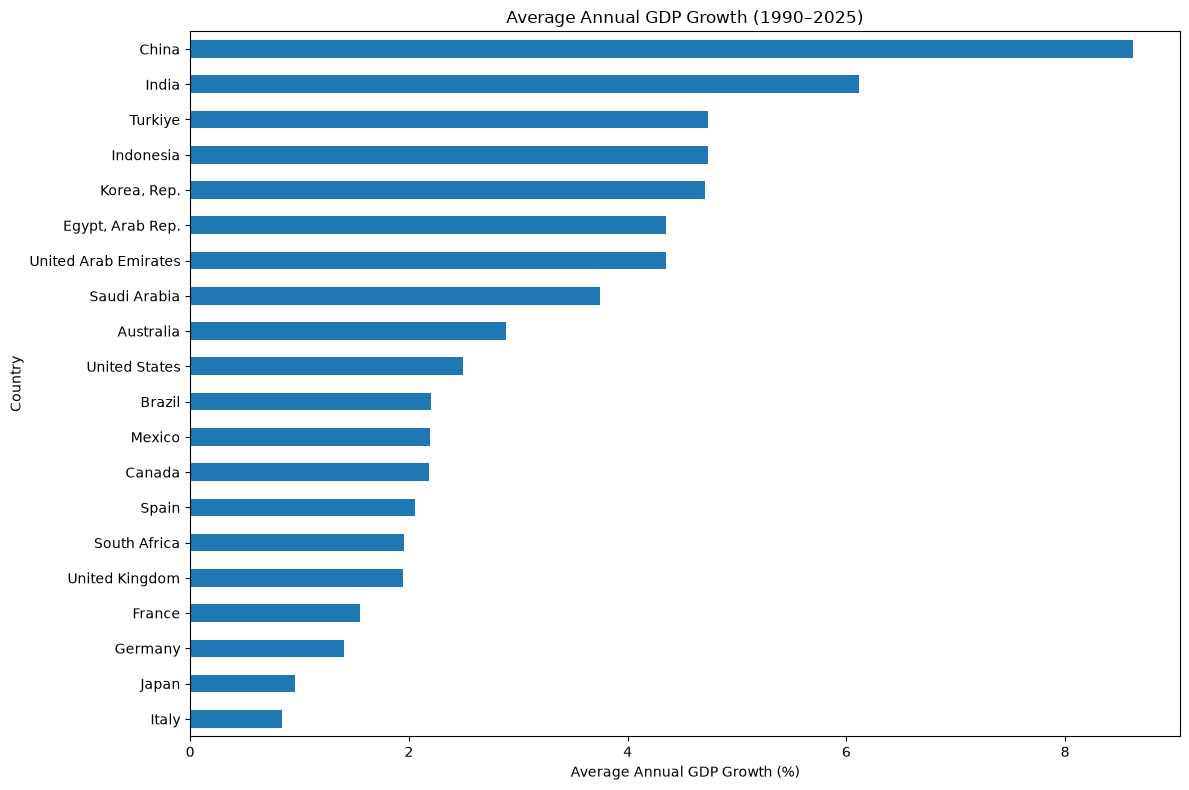

In [28]:
# GDP Growth Visualization — Country Ranking
average_growth.sort_values().plot(
    kind='barh',
    figsize=(12, 8)
)

plt.title('Average Annual GDP Growth (1990–2025)')
plt.xlabel('Average Annual GDP Growth (%)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


### Country Comparison — Select Four Economies

اختيار مصر والصين وأمريكا وألمانيا لدراسة سلوك النمو عبر الزمن.

In [29]:
# Country Comparison — Select Four Economies
countries = [
    'Egypt, Arab Rep.',
    'China',
    'United States',
    'Germany'
]

selected_data = gdp_growth[
    gdp_growth['Country Name'].isin(countries)
]

selected_data.head()


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value,Data_Status
720,China,CHN,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1990,3.922520,Available
721,China,CHN,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1991,9.375632,Available
722,China,CHN,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1992,14.297623,Available
723,China,CHN,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1993,13.926103,Available
724,China,CHN,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,1994,13.082712,Available


### Time Series Transformation — GDP Pivot

تحويل البيانات الطويلة لجدول تكون فيه السنوات صفوفًا والدول أعمدة.

In [30]:
# Time Series Transformation — GDP Pivot
growth_pivot = selected_data.pivot(
    index='Year',
    columns='Country Name',
    values='Value'
)

growth_pivot.head()


Country Name,China,"Egypt, Arab Rep.",Germany,United States
Year,,,,
1990,3.922520,5.667029,5.255006,1.885966
1991,9.375632,1.125405,5.108262,-0.108313
1992,14.297623,4.472859,2.013613,3.522497
1993,13.926103,2.900791,-0.973033,2.751796
1994,13.082712,3.973172,2.596856,4.029023


### Time Series Shape — Validate Pivot

التحقق من أبعاد جدول النمو للسنوات والدول المختارة.

In [31]:
# Time Series Shape — Validate Pivot
growth_pivot.shape


(36, 4)

### GDP Growth Trends — Multi-Country Line Chart

رسم تطور النمو السنوي مع خط مرجعي عند الصفر لتمييز الانكماش.

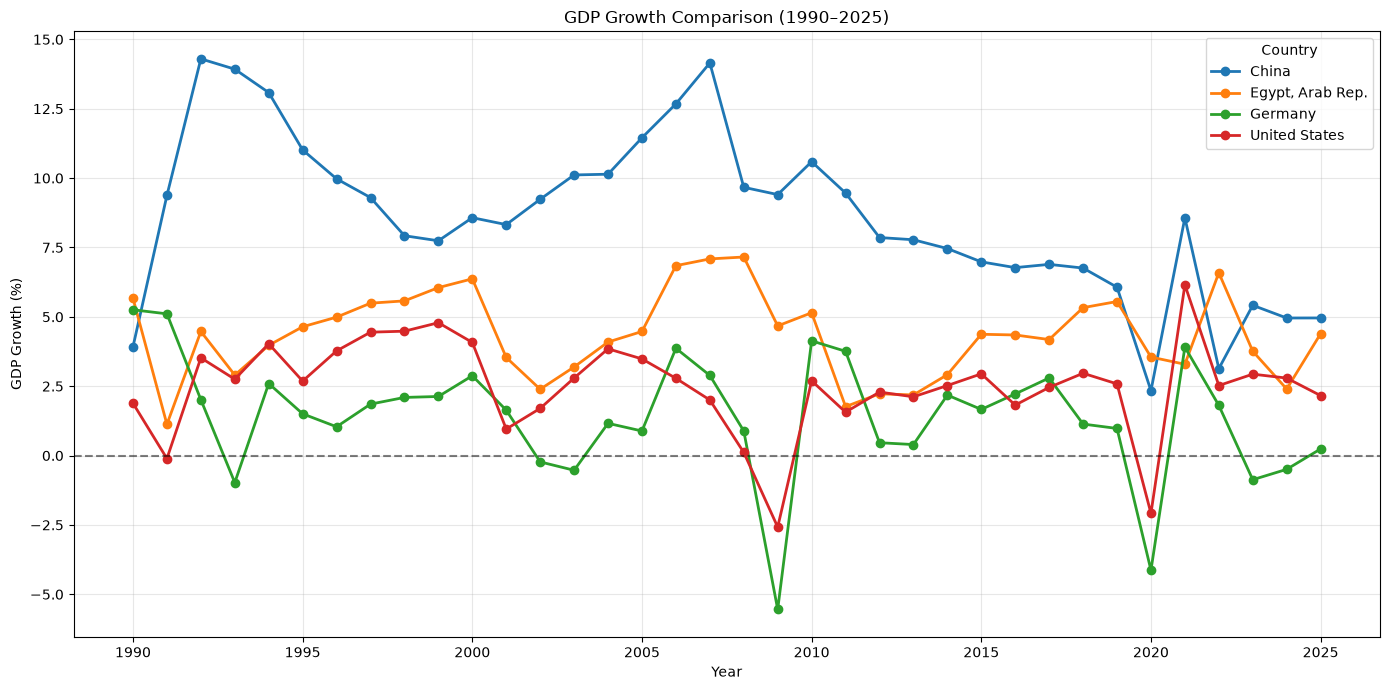

In [32]:
# GDP Growth Trends — Multi-Country Line Chart
growth_pivot.plot(
    kind='line',
    figsize=(14, 7),
    marker='o',
    linewidth=2
)

plt.title('GDP Growth Comparison (1990–2025)')
plt.xlabel('Year')
plt.ylabel('GDP Growth (%)')
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)
plt.grid(True, alpha=0.3)
plt.legend(title='Country')
plt.tight_layout()
plt.show()


### Economic Shocks — 2009 & 2020

مقارنة النمو المسجل خلال سنتين شهدتا صدمات اقتصادية عالمية.

In [33]:
# Economic Shocks — 2009 & 2020
growth_pivot.loc[[2009, 2020]]


Country Name,China,"Egypt, Arab Rep.",Germany,United States
Year,,,,
2009,9.406100,4.673600,-5.544555,-2.576500
2020,2.339504,3.550165,-4.131914,-2.081376


### GDP Risk — Growth Volatility

حساب الانحراف المعياري لمعدلات نمو كل دولة خلال الفترة المختارة.

In [34]:
# GDP Risk — Growth Volatility
volatility = growth_pivot.std()

volatility


Country Name
China               2.961331
Egypt, Arab Rep.    1.551263
Germany             2.195954
United States       1.708200
dtype: float64

### GDP Risk — Stability Ranking

ترتيب الدول من الأقل تقلبًا إلى الأعلى.

In [35]:
# GDP Risk — Stability Ranking
volatility.sort_values(ascending=True)


Country Name
Egypt, Arab Rep.    1.551263
United States       1.708200
Germany             2.195954
China               2.961331
dtype: float64

### GDP Contractions — Negative Growth Years

تحديد وعدّ السنوات التي كان فيها النمو الاقتصادي سالبًا.

In [36]:
# GDP Contractions — Negative Growth Years
negative_growth = growth_pivot < 0

negative_growth.sum()


Country Name
China               0
Egypt, Arab Rep.    0
Germany             7
United States       3
dtype: int64

### GDP Summary — Mean Growth

حساب متوسط نمو الدول الأربع لمقارنته بالتقلب.

In [37]:
# GDP Summary — Mean Growth
avg_growth = growth_pivot.mean()

avg_growth


Country Name
China               8.619410
Egypt, Arab Rep.    4.353017
Germany             1.408769
United States       2.496943
dtype: float64

### GDP Summary — Recession Counts

حفظ عدد سنوات النمو السالب لكل دولة.

In [38]:
# GDP Summary — Recession Counts
negative_years = negative_growth.sum()

negative_years


Country Name
China               0
Egypt, Arab Rep.    0
Germany             7
United States       3
dtype: int64

### Economic Performance Report — Summary Table

جمع متوسط النمو والتقلب وعدد السنوات السالبة في جدول واحد.

In [39]:
# Economic Performance Report — Summary Table
economic_report = pd.DataFrame({
    'Average Growth': avg_growth,
    'Volatility': volatility,
    'Negative Years': negative_years
})

economic_report.round(2)


,Average Growth,Volatility,Negative Years
Country Name,,,
China,8.62,2.96,0
"Egypt, Arab Rep.",4.35,1.55,0
Germany,1.41,2.20,7
United States,2.50,1.71,3


### Economic Performance Report — Growth Ranking

ترتيب تقرير الدول حسب متوسط النمو السنوي.

In [40]:
# Economic Performance Report — Growth Ranking
economic_report.sort_values(
    by='Average Growth',
    ascending=False
)


,Average Growth,Volatility,Negative Years
Country Name,,,
China,8.619410,2.961331,0
"Egypt, Arab Rep.",4.353017,1.551263,0
United States,2.496943,1.708200,3
Germany,1.408769,2.195954,7


---

## 04 · Inflation, Unemployment & Outliers

إحصاءات التضخم والبطالة وتحليل القيم المتطرفة في البرازيل.

### Inflation Data Extraction

استخراج سجلات التضخم باستخدام كود مؤشر أسعار المستهلك.

In [41]:
# Inflation Data Extraction
inflation = df_clean[
    df_clean['Indicator Code'] == 'FP.CPI.TOTL.ZG'
]

inflation.head()


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value,Data_Status
36,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1990,NaN,Missing
37,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1991,NaN,Missing
38,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1992,NaN,Missing
39,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1993,NaN,Missing
40,United Arab Emirates,ARE,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1994,NaN,Missing


### Unemployment Data Extraction

استخراج سجلات البطالة باستخدام كود المؤشر المناسب.

In [42]:
# Unemployment Data Extraction
unemployment = df_clean[
    df_clean['Indicator Code'] == 'SL.UEM.TOTL.ZS'
]

unemployment.head()


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value,Data_Status
72,United Arab Emirates,ARE,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,1990,NaN,Missing
73,United Arab Emirates,ARE,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,1991,1.629,Available
74,United Arab Emirates,ARE,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,1992,1.715,Available
75,United Arab Emirates,ARE,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,1993,1.901,Available
76,United Arab Emirates,ARE,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,1994,1.834,Available


### Inflation Statistics — Mean by Country

حساب متوسط التضخم التاريخي لكل دولة.

In [43]:
# Inflation Statistics — Mean by Country
avg_inflation = (
    inflation
    .groupby('Country Name')['Value']
    .mean()
    .sort_values(ascending=False)
)

avg_inflation


Country Name
Brazil                  238.733333
Turkiye                  37.496993
Egypt, Arab Rep.         11.274613
Mexico                    9.079178
Indonesia                 8.137875
India                     6.948549
South Africa              6.478032
China                     3.557091
Korea, Rep.               3.385796
Spain                     2.897502
United Kingdom            2.823441
Australia                 2.772115
United States             2.698436
Italy                     2.612718
Canada                    2.216855
Germany                   2.089445
United Arab Emirates      2.022319
Saudi Arabia              1.982621
France                    1.731403
Japan                     0.712014
Name: Value, dtype: float64

### Unemployment Statistics — Mean by Country

حساب متوسط البطالة التاريخي لكل دولة.

In [44]:
# Unemployment Statistics — Mean by Country
avg_unemployment = (
    unemployment
    .groupby('Country Name')['Value']
    .mean()
    .sort_values(ascending=False)
)

avg_unemployment


Country Name
South Africa            25.242571
Spain                   16.415143
Turkiye                  9.779714
Egypt, Arab Rep.         9.677486
Italy                    9.604571
France                   9.494257
Brazil                   9.247714
Canada                   7.668971
India                    7.180571
Germany                  6.637314
Australia                6.215286
United Kingdom           6.171029
United States            5.677600
Saudi Arabia             5.621371
Indonesia                4.961429
China                    4.085571
Mexico                   3.892371
Japan                    3.617686
Korea, Rep.              3.320286
United Arab Emirates     2.397771
Name: Value, dtype: float64

### Inflation Statistics — Median by Country

حساب الوسيط لتقليل تأثير القيم التاريخية المتطرفة.

In [45]:
# Inflation Statistics — Median by Country
median_inflation = (
    inflation
    .groupby('Country Name')['Value']
    .median()
    .sort_values(ascending=False)
)

median_inflation


Country Name
Turkiye                 20.599460
Egypt, Arab Rep.        10.067571
Brazil                   6.616817
Indonesia                6.379025
India                    6.349886
South Africa             5.759070
Mexico                   5.077855
Spain                    3.039310
Korea, Rep.              2.759379
United States            2.677237
Australia                2.551654
United Kingdom           2.339701
Italy                    2.066975
China                    2.037396
Canada                   1.975647
Saudi Arabia             1.935399
Germany                  1.685949
France                   1.673405
United Arab Emirates     1.589651
Japan                    0.292197
Name: Value, dtype: float64

### Inflation Report — Mean vs Median

مقارنة المتوسط والوسيط في تقرير واحد لتوضيح أثر القيم الشاذة.

In [46]:
# Inflation Report — Mean vs Median
inflation_report = pd.DataFrame({
    'Mean Inflation': avg_inflation,
    'Median Inflation': median_inflation
})

inflation_report.round(2)


,Mean Inflation,Median Inflation
Country Name,,
Australia,2.77,2.55
Brazil,238.73,6.62
Canada,2.22,1.98
China,3.56,2.04
"Egypt, Arab Rep.",11.27,10.07
France,1.73,1.67
Germany,2.09,1.69
India,6.95,6.35
Indonesia,8.14,6.38


### Outlier Investigation — Brazil

تحديد أعلى سنوات التضخم المسجلة في البرازيل.

In [47]:
# Outlier Investigation — Brazil
brazil_inflation = inflation[
    inflation['Country Name'] == 'Brazil'
]

brazil_inflation[
    ['Year', 'Value']
].sort_values(
    by='Value',
    ascending=False
).head(5)


,Year,Value
396,1990,2947.732772
400,1994,2075.888398
399,1993,1927.380790
398,1992,951.962053
397,1991,432.786662


### Brazil Inflation — From 1995

تلخيص التضخم البرازيلي بعد 1994.

In [48]:
# Brazil Inflation — From 1995
brazil_after = brazil_inflation[
    brazil_inflation['Year'] >= 1995
]

brazil_after['Value'].agg(
    ['count', 'mean', 'median']
)


count     31.000000
mean       8.343526
median     6.204311
Name: Value, dtype: float64

### Brazil Inflation — Before 1995

تلخيص التضخم البرازيلي حتى 1994.

In [49]:
# Brazil Inflation — Before 1995
brazil_before = brazil_inflation[
    brazil_inflation['Year'] <= 1994
]

brazil_before['Value'].agg(
    ['count', 'mean', 'median']
)


count        5.000000
mean      1667.150135
median    1927.380790
Name: Value, dtype: float64

### Brazil Inflation Comparison — First Pass

مقارنة فترتين تاريخيتين باستخدام المتوسط والوسيط.

In [50]:
# Brazil Inflation Comparison — First Pass
comparison = pd.DataFrame({
    'Period': ['Before 1995', 'From 1995'],

    'Mean Inflation': [
        brazil_before['Value'].mean(),
        brazil_after['Value'].mean()
    ],

    'Median Inflation': [
        brazil_before['Value'].median(),
        brazil_after['Value'].median()
    ]
})

comparison.round(2)


,Period,Mean Inflation,Median Inflation
0,Before 1995,1667.15,1927.38
1,From 1995,8.34,6.20


### Brazil Inflation — Explicit Period Filters

توضيح مرشحات الفترتين قبل عرض المقارنة النهائية.

In [51]:
# Brazil Inflation — Explicit Period Filters
# Before 1995
brazil_before = brazil_inflation[
    brazil_inflation['Year'] <= 1994
]

# From 1995
brazil_after = brazil_inflation[
    brazil_inflation['Year'] >= 1995
]


### Brazil Inflation — Period Sample Sizes

مراجعة عدد السجلات المستخدمة في كل فترة.

In [52]:
# Brazil Inflation — Period Sample Sizes
print("Before:", len(brazil_before))
print("After:", len(brazil_after))


Before: 5
After: 31


### Brazil Inflation — Final Comparison

إخراج جدول المقارنة النهائي بين الفترتين.

In [53]:
# Brazil Inflation — Final Comparison
comparison = pd.DataFrame({
    'Period': ['Before 1995', 'From 1995'],

    'Mean Inflation': [
        brazil_before['Value'].mean(),
        brazil_after['Value'].mean()
    ],

    'Median Inflation': [
        brazil_before['Value'].median(),
        brazil_after['Value'].median()
    ]
})

comparison.round(2)


,Period,Mean Inflation,Median Inflation
0,Before 1995,1667.15,1927.38
1,From 1995,8.34,6.20


---

## 05 · Wide Data & Correlation Analysis

تحويل البيانات إلى شكل Country-Year وتحليل ارتباط المؤشرات.

### Data Transformation — Multi-Indicator Pivot

جمع النمو والتضخم والبطالة في جدول Country-Year موحّد.

In [54]:
# Data Transformation — Multi-Indicator Pivot
indicators = [
    'NY.GDP.MKTP.KD.ZG',
    'FP.CPI.TOTL.ZG',
    'SL.UEM.TOTL.ZS'
]

economic_data = df_clean[
    df_clean['Indicator Code'].isin(indicators)
]

economic_pivot = economic_data.pivot(
    index=['Country Name', 'Year'],
    columns='Indicator Code',
    values='Value'
)

economic_pivot.head()


Indicator Code     FP.CPI.TOTL.ZG  NY.GDP.MKTP.KD.ZG  SL.UEM.TOTL.ZS
Country Name Year                                                   
Australia    1990        7.333024           3.572976             NaN
             1991        3.176669          -0.384631           9.586
             1992        1.012228           0.433066          10.733
             1993        1.753658           4.045834          10.879
             1994        1.969635           3.978844           9.724

### Pivot Validation — Dataset Shape

التأكد من عدد صفوف وأعمدة الـPivot.

In [55]:
# Pivot Validation — Dataset Shape
economic_pivot.shape


(720, 3)

### Pivot Quality Check — Null Values

قياس القيم الناقصة في المؤشرات الثلاثة بعد التحويل.

In [56]:
# Pivot Quality Check — Null Values
economic_pivot.isna().sum()


Indicator Code
FP.CPI.TOTL.ZG       19
NY.GDP.MKTP.KD.ZG     1
SL.UEM.TOTL.ZS       20
dtype: int64

### Feature Schema — Human-Readable Column Names

إعادة تسمية أكواد المؤشرات بأسماء واضحة وتحويل الدولة والسنة لأعمدة عادية.

In [57]:
# Feature Schema — Human-Readable Column Names
economic_pivot = economic_pivot.rename(columns={
    'FP.CPI.TOTL.ZG': 'Inflation',
    'NY.GDP.MKTP.KD.ZG': 'GDP_Growth',
    'SL.UEM.TOTL.ZS': 'Unemployment'
})
economic_pivot = economic_pivot.reset_index()
economic_pivot.columns.name = None   # Clear the 'Indicator Code' table header.
economic_pivot.head()


,Country Name,Year,Inflation,GDP_Growth,Unemployment
0,Australia,1990,7.333024,3.572976,NaN
1,Australia,1991,3.176669,-0.384631,9.586
2,Australia,1992,1.012228,0.433066,10.733
3,Australia,1993,1.753658,4.045834,10.879
4,Australia,1994,1.969635,3.978844,9.724


### Correlation Study — Egypt Data

اختيار السجلات السنوية الخاصة بمصر.

In [58]:
# Correlation Study — Egypt Data
egypt_data = economic_pivot[
    economic_pivot['Country Name'] == 'Egypt, Arab Rep.'
]

egypt_data.head()


,Country Name,Year,Inflation,GDP_Growth,Unemployment
144,"Egypt, Arab Rep.",1990,16.756375,5.667029,NaN
145,"Egypt, Arab Rep.",1991,19.748545,1.125405,9.38
146,"Egypt, Arab Rep.",1992,13.637424,4.472859,8.92
147,"Egypt, Arab Rep.",1993,12.089792,2.900791,10.92
148,"Egypt, Arab Rep.",1994,8.154231,3.973172,10.93


### Correlation Matrix — Egypt

حساب معاملات الارتباط بين النمو والتضخم والبطالة لمصر.

In [59]:
# Correlation Matrix — Egypt
egypt_corr = egypt_data[
    ['GDP_Growth', 'Inflation', 'Unemployment']
].corr()

egypt_corr.round(2)


,GDP_Growth,Inflation,Unemployment
GDP_Growth,1.00,-0.11,-0.37
Inflation,-0.11,1.00,-0.14
Unemployment,-0.37,-0.14,1.00


### Correlation Visualization — Heatmap

عرض معاملات الارتباط في خريطة حرارية سهلة القراءة.

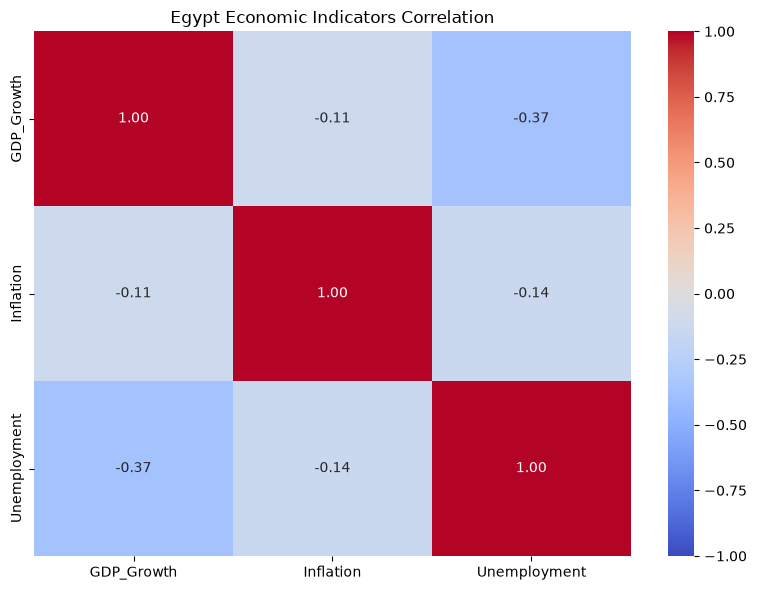

In [60]:
# Correlation Visualization — Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    egypt_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Egypt Economic Indicators Correlation')
plt.tight_layout()
plt.show()


### Correlation Study — United States Data

اختيار بيانات الولايات المتحدة.

In [61]:
# Correlation Study — United States Data
usa_data = economic_pivot[
    economic_pivot['Country Name'] == 'United States'
]


### Correlation Matrix — United States

حساب مصفوفة ارتباط المؤشرات الأمريكية.

In [62]:
# Correlation Matrix — United States
usa_corr = usa_data[
    ['GDP_Growth', 'Inflation', 'Unemployment']
].corr()

usa_corr.round(2)


,GDP_Growth,Inflation,Unemployment
GDP_Growth,1.00,0.23,-0.46
Inflation,0.23,1.00,-0.36
Unemployment,-0.46,-0.36,1.00


### Correlation Matrix — China

حساب ارتباط النمو والتضخم والبطالة في الصين.

In [63]:
# Correlation Matrix — China
china_data = economic_pivot[
    economic_pivot['Country Name'] == 'China'
]

china_corr = china_data[
    ['GDP_Growth', 'Inflation', 'Unemployment']
].corr()

china_corr.round(2)


,GDP_Growth,Inflation,Unemployment
GDP_Growth,1.00,0.51,-0.53
Inflation,0.51,1.00,-0.50
Unemployment,-0.53,-0.50,1.00


### Correlation Matrix — Germany

حساب ارتباط المؤشرات الألمانية للمقارنة مع الدول الأخرى.

In [64]:
# Correlation Matrix — Germany
Germany_data = economic_pivot[
    economic_pivot['Country Name'] == 'Germany'
]

Germany_corr = Germany_data[
    ['GDP_Growth', 'Inflation', 'Unemployment']
].corr()

Germany_corr.round(2)


,GDP_Growth,Inflation,Unemployment
GDP_Growth,1.00,0.16,0.07
Inflation,0.16,1.00,-0.27
Unemployment,0.07,-0.27,1.00


---

## 06 · Feature Engineering for Time Series

إعداد مدخلات تعتمد على السنوات السابقة فقط لتجنّب Data Leakage.

### ML Preparation — Sort Panel Data

ترتيب السنوات داخل كل دولة قبل إنشاء Features زمنية.

In [65]:
# ML Preparation — Sort Panel Data
df_features = economic_pivot.sort_values(
    by=['Country Name', 'Year']
).copy()

df_features.head()


,Country Name,Year,Inflation,GDP_Growth,Unemployment
0,Australia,1990,7.333024,3.572976,NaN
1,Australia,1991,3.176669,-0.384631,9.586
2,Australia,1992,1.012228,0.433066,10.733
3,Australia,1993,1.753658,4.045834,10.879
4,Australia,1994,1.969635,3.978844,9.724


### Feature Engineering — GDP Lag 1

استخدام نمو السنة السابقة كمدخل لتوقع نمو السنة الحالية.

In [66]:
# Feature Engineering — GDP Lag 1
df_features['GDP_Lag1'] = (
    df_features
    .groupby('Country Name')['GDP_Growth']
    .shift(1)
)


### Feature QA — Review Egypt GDP Lag

التأكد من أن `GDP_Lag1` لا يسحب بيانات دولة أو سنة خاطئة.

In [67]:
# Feature QA — Review Egypt GDP Lag
df_features[
    df_features['Country Name'] == 'Egypt, Arab Rep.'
][['Year', 'GDP_Growth', 'GDP_Lag1']].head(10)


,Year,GDP_Growth,GDP_Lag1
144,1990,5.667029,NaN
145,1991,1.125405,5.667029
146,1992,4.472859,1.125405
147,1993,2.900791,4.472859
148,1994,3.973172,2.900791
149,1995,4.642459,3.973172
150,1996,4.988731,4.642459
151,1997,5.492355,4.988731
152,1998,5.575497,5.492355
153,1999,6.053439,5.575497


### Feature Engineering — 3-Year Rolling GDP

حساب متوسط نمو آخر 3 سنوات **سابقة فقط** باستخدام `shift(1)`.

In [68]:
# Feature Engineering — 3-Year Rolling GDP
df_features['GDP_Rolling3'] = (
    df_features
    .groupby('Country Name')['GDP_Growth']
    .transform(
        lambda x: x.shift(1).rolling(
            window=3,
            min_periods=3
        ).mean()
    )
)


### Feature QA — Validate Rolling Window

فحص بداية قيم المتوسط المتحرك والتأكد من التعامل الصحيح مع أول 3 سنوات.

In [69]:
# Feature QA — Validate Rolling Window
df_features[
    df_features['Country Name'] == 'Egypt, Arab Rep.'
][
    ['Year', 'GDP_Growth', 'GDP_Lag1', 'GDP_Rolling3']
].head(10)


,Year,GDP_Growth,GDP_Lag1,GDP_Rolling3
144,1990,5.667029,NaN,NaN
145,1991,1.125405,5.667029,NaN
146,1992,4.472859,1.125405,NaN
147,1993,2.900791,4.472859,3.755098
148,1994,3.973172,2.900791,2.833018
149,1995,4.642459,3.973172,3.782274
150,1996,4.988731,4.642459,3.838807
151,1997,5.492355,4.988731,4.534787
152,1998,5.575497,5.492355,5.041181
153,1999,6.053439,5.575497,5.352194


### Feature Engineering — Inflation Lag 1

إضافة معدل التضخم في السنة السابقة بدل التضخم في سنة التوقع.

In [70]:
# Feature Engineering — Inflation Lag 1
df_features['Inflation_Lag1'] = (
    df_features.groupby('Country Name')['Inflation'].shift(1)
)

df_features[
    df_features['Country Name'] == 'Egypt, Arab Rep.'
][['Year', 'Inflation', 'Inflation_Lag1']].head(10)


,Year,Inflation,Inflation_Lag1
144,1990,16.756375,NaN
145,1991,19.748545,16.756375
146,1992,13.637424,19.748545
147,1993,12.089792,13.637424
148,1994,8.154231,12.089792
149,1995,15.742231,8.154231
150,1996,7.187104,15.742231
151,1997,4.625606,7.187104
152,1998,3.872575,4.625606
153,1999,3.079499,3.872575


### Feature Engineering — Lagged Unemployment Change

حساب فرق البطالة بين السنتين السابقتين دون استخدام قيمة سنة التوقع.

In [71]:
# Feature Engineering — Lagged Unemployment Change
df_features['Unemployment_Change'] = (
    df_features
    .groupby('Country Name')['Unemployment']
    .transform(lambda x: x.diff().shift(1))
)

df_features[
    df_features['Country Name'] == 'Egypt, Arab Rep.'
][
    ['Year', 'Unemployment', 'Unemployment_Change']
].head(10)


,Year,Unemployment,Unemployment_Change
144,1990,NaN,NaN
145,1991,9.38,NaN
146,1992,8.92,NaN
147,1993,10.92,-0.46
148,1994,10.93,2.00
149,1995,11.04,0.01
150,1996,9.00,0.11
151,1997,8.37,-2.04
152,1998,8.03,-0.63
153,1999,7.95,-0.34


---

## 07 · ML Dataset, Baseline & First Models

تعريف X وy، تقسيم زمني وتدريب أول نماذج Machine Learning.

### ML Dataset — Define Features & Target

تحديد الأعمدة الأربعة المُدخلة والمتغير الهدف GDP Growth واستبعاد صفوف التدريب غير المكتملة.

In [72]:
# ML Dataset — Define Features & Target
features = [
    'GDP_Lag1',
    'GDP_Rolling3',
    'Inflation_Lag1',
    'Unemployment_Change'
]

target = 'GDP_Growth'

df_model = df_features[
    ['Country Name', 'Year'] + features + [target]
].dropna().copy()

print("Dataset Shape:", df_model.shape)

df_model.head(10)


Dataset Shape: (643, 7)


,Country Name,Year,GDP_Lag1,GDP_Rolling3,Inflation_Lag1,Unemployment_Change,GDP_Growth
3,Australia,1993,0.433066,1.207137,1.012228,1.147,4.045834
4,Australia,1994,4.045834,1.364756,1.753658,0.146,3.978844
5,Australia,1995,3.978844,2.819248,1.969635,-1.155,3.890172
6,Australia,1996,3.890172,3.971617,4.627764,-1.251,3.865675
7,Australia,1997,3.865675,3.911564,2.615379,0.036,3.917958
8,Australia,1998,3.917958,3.891268,0.224895,-0.142,4.676814
9,Australia,1999,4.676814,4.153482,0.860130,-0.683,5.028220
10,Australia,2000,5.028220,4.540997,1.483139,-0.808,3.916057
11,Australia,2001,3.916057,4.540364,4.457437,-0.588,2.031459
12,Australia,2002,2.031459,3.658579,4.407130,0.459,3.949805


### Time-Based Split — Train 1993–2019 / Test 2020–2025

تقسيم البيانات زمنيًا بدل التقسيم العشوائي لتقليل خطر تسرّب المستقبل.

In [73]:
# Time-Based Split — Train 1993–2019 / Test 2020–2025
train = df_model[df_model['Year'] <= 2019]
test = df_model[df_model['Year'] >= 2020]

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (524, 4)
y_train: (524,)
X_test: (119, 4)
y_test: (119,)


### Model Training — Linear Regression

تدريب نموذج انحدار خطي وحساب توقعاته على سنوات الاختبار.

In [74]:
# Model Training — Linear Regression
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Predictions:", len(y_pred))
print("First 10 Predictions:", y_pred[:10])


Model trained successfully!
Predictions: 119
First 10 Predictions: [2.50438381 2.00379086 1.60882996 2.64450802 3.32108731 2.62262693
 1.75525893 0.54261372 2.72897565 1.00734   ]


### Model Evaluation — MAE, RMSE & R²

تقييم دقة النموذج بثلاث مقاييس مكملة لبعضها.

In [75]:
# Model Evaluation — MAE, RMSE & R²
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)

rmse = mean_squared_error(y_test, y_pred) ** 0.5

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))


MAE: 3.0879
RMSE: 4.4901
R2 Score: -0.1785


### Baseline Model — Previous-Year GDP

مقارنة النموذج بطريقة بسيطة تفترض تكرار نمو السنة السابقة.

In [76]:
# Baseline Model — Previous-Year GDP
baseline_pred = test['GDP_Lag1']

baseline_mae = mean_absolute_error(
    y_test, baseline_pred
)

baseline_rmse = mean_squared_error(
    y_test, baseline_pred
) ** 0.5

baseline_r2 = r2_score(
    y_test, baseline_pred
)

comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Baseline'],
    'MAE': [mae, baseline_mae],
    'RMSE': [rmse, baseline_rmse],
    'R2': [r2, baseline_r2]
})

comparison.round(4)


,Model,MAE,RMSE,R2
0,Linear Regression,3.0879,4.4901,-0.1785
1,Baseline,3.8995,5.8786,-1.0200


### Error Analysis — Yearly MAE

عرض متوسط الخطأ حسب السنة لاكتشاف الفترات الصعبة.

In [77]:
# Error Analysis — Yearly MAE
yearly_errors = test[['Year']].copy()

yearly_errors['LR_Error'] = abs(
    y_test.to_numpy() - y_pred
)

yearly_errors['Baseline_Error'] = abs(
    y_test.to_numpy() - baseline_pred.to_numpy()
)

yearly_report = (
    yearly_errors
    .groupby('Year')[['LR_Error', 'Baseline_Error']]
    .mean()
    .round(3)
)

yearly_report


,LR_Error,Baseline_Error
Year,,
2020,6.738,6.314
2021,6.044,10.284
2022,2.157,2.972
2023,1.437,2.257
2024,1.125,0.734
2025,0.917,0.675


### Period Analysis — 2022–2025

تحليل إضافي لأداء النموذج في السنوات الحديثة دون استبدال الاختبار الأصلي.

In [78]:
# Period Analysis — 2022–2025
mask = test['Year'] >= 2022

y_test_recent = y_test.loc[mask]
y_pred_recent = y_pred[mask.to_numpy()]

recent_mae = mean_absolute_error(
    y_test_recent, y_pred_recent
)

recent_rmse = mean_squared_error(
    y_test_recent, y_pred_recent
) ** 0.5

recent_r2 = r2_score(
    y_test_recent, y_pred_recent
)

recent_comparison = pd.DataFrame({
    'Period': ['2020-2025', '2022-2025'],
    'MAE': [mae, recent_mae],
    'RMSE': [rmse, recent_rmse],
    'R2': [r2, recent_r2]
})

recent_comparison.round(4)


,Period,MAE,RMSE,R2
0,2020-2025,3.0879,4.4901,-0.1785
1,2022-2025,1.4154,1.9635,0.2590


### Model Training — Random Forest

تدريب Random Forest ومقارنته بالـBaseline والانحدار الخطي.

In [79]:
# Model Training — Random Forest
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = mean_squared_error(y_test, rf_pred) ** 0.5
rf_r2 = r2_score(y_test, rf_pred)

model_comparison = pd.DataFrame({
    'Model': [
        'Baseline',
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [baseline_mae, mae, rf_mae],
    'RMSE': [baseline_rmse, rmse, rf_rmse],
    'R2': [baseline_r2, r2, rf_r2]
})

model_comparison.round(4)


,Model,MAE,RMSE,R2
0,Baseline,3.8995,5.8786,-1.0200
1,Linear Regression,3.0879,4.4901,-0.1785
2,Random Forest,2.5592,3.7674,0.1704


---

## 08 · Model Diagnostics & Explainability

معرفة مواضع خطأ النماذج والمميزات المستخدمة بكثافة.

### Model Explainability — Feature Importance

رسم درجة أهمية كل Feature داخل الغابة العشوائية؛ الأهمية لا تعني السببية.

               Feature  Importance
0             GDP_Lag1    0.685756
1         GDP_Rolling3    0.168327
2       Inflation_Lag1    0.092969
3  Unemployment_Change    0.052949


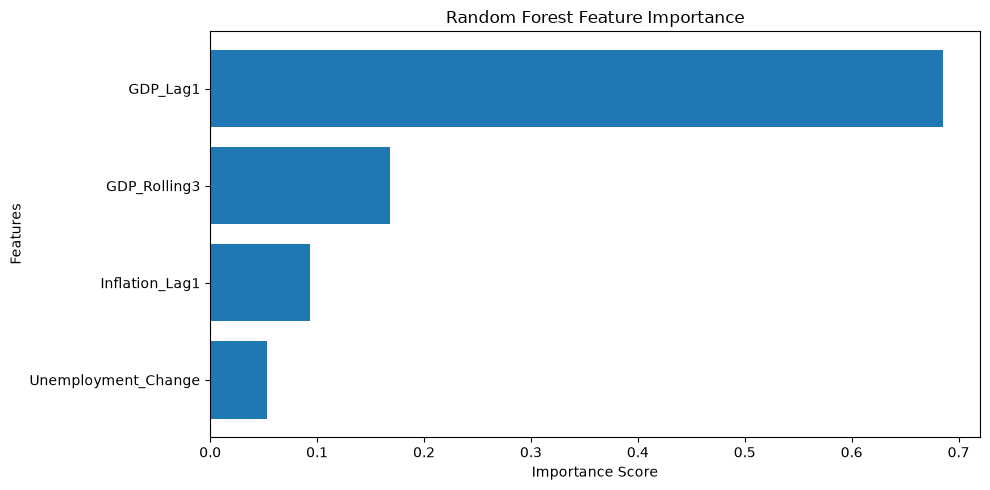

In [80]:
# Model Explainability — Feature Importance
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10, 5))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.gca().invert_yaxis()

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.tight_layout()
plt.show()


### Model Diagnostics — Error by Country

حساب متوسط الخطأ في كل دولة لاكتشاف اختلاف مستوى الأداء.

In [81]:
# Model Diagnostics — Error by Country
country_predictions = test[
    ['Country Name', 'Year', 'GDP_Growth']
].copy()

country_predictions['Predicted_GDP'] = rf_pred

country_predictions['Error'] = abs(
    country_predictions['GDP_Growth']
    - country_predictions['Predicted_GDP']
)

country_report = (
    country_predictions
    .groupby('Country Name')['Error']
    .mean()
    .sort_values(ascending=False)
)

country_report.round(3)


Country Name
Saudi Arabia            5.063
United Kingdom          3.773
Italy                   3.539
Spain                   3.395
United Arab Emirates    3.370
India                   3.343
France                  2.912
China                   2.652
Mexico                  2.632
Turkiye                 2.485
Indonesia               2.274
Germany                 2.185
South Africa            2.122
United States           2.085
Brazil                  1.920
Canada                  1.712
Japan                   1.608
Australia               1.448
Korea, Rep.             1.434
Egypt, Arab Rep.        1.369
Name: Error, dtype: float64

### Case Study — Saudi Arabia Prediction Errors

فحص التوقعات مقابل القيم الحقيقية للسعودية عامًا بعد عام.

In [82]:
# Case Study — Saudi Arabia Prediction Errors
saudi_analysis = country_predictions[
    country_predictions['Country Name'] == 'Saudi Arabia'
][
    ['Year', 'GDP_Growth', 'Predicted_GDP', 'Error']
].sort_values('Year')

saudi_analysis.round(3)


,Year,GDP_Growth,Predicted_GDP,Error
498,2020,-3.805,1.717,5.521
499,2021,6.520,0.344,6.175
500,2022,12.001,4.173,7.827
501,2023,0.543,7.542,7.000
502,2024,2.649,0.574,2.075
503,2025,4.502,2.723,1.779


---

## 09 · Validation & Hyperparameter Tuning

ضبط النماذج بناءً على فترات تاريخية، وليس بناءً على Test.

### Validation Setup — Holdout 2017–2019

عزل فترة Validation سابقة للاختبار من أجل تقييم قرارات تطوير النموذج.

In [83]:
# Validation Setup — Holdout 2017–2019
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

val_train = df_model[df_model['Year'] <= 2016]
val_test = df_model[
    df_model['Year'].between(2017, 2019)
]

rf_val = RandomForestRegressor(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_val.fit(
    val_train[features],
    val_train[target]
)

val_pred = rf_val.predict(
    val_test[features]
)

val_comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Baseline'],

    'MAE': [
        mean_absolute_error(val_test[target], val_pred),
        mean_absolute_error(
            val_test[target],
            val_test['GDP_Lag1']
        )
    ],

    'RMSE': [
        mean_squared_error(
            val_test[target], val_pred
        ) ** 0.5,
        mean_squared_error(
            val_test[target],
            val_test['GDP_Lag1']
        ) ** 0.5
    ],

    'R2': [
        r2_score(val_test[target], val_pred),
        r2_score(
            val_test[target],
            val_test['GDP_Lag1']
        )
    ]
})

print("Training:", val_train.shape)
print("Validation:", val_test.shape)

val_comparison.round(4)


Training: (464, 7)
Validation: (60, 7)


,Model,MAE,RMSE,R2
0,Random Forest,0.9664,1.4402,0.4458
1,Baseline,1.0402,1.6459,0.2762


### Hyperparameter Search — Random Forest Grid

اختبار أعماق الأشجار وحجم الأوراق لاختيار إعدادات جيدة بالـValidation.

In [84]:
# Hyperparameter Search — Random Forest Grid
results = []

for depth in [4, 6, 8]:
    for leaf in [2, 3, 5]:

        model_temp = RandomForestRegressor(
            n_estimators=200,
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=42,
            n_jobs=-1
        )

        model_temp.fit(
            val_train[features],
            val_train[target]
        )

        pred_temp = model_temp.predict(
            val_test[features]
        )

        score = mean_absolute_error(
            val_test[target],
            pred_temp
        )

        results.append({
            'Max_Depth': depth,
            'Min_Samples_Leaf': leaf,
            'MAE': score
        })

tuning_results = pd.DataFrame(results)

tuning_results = tuning_results.sort_values(
    by='MAE'
)

tuning_results.round(4)


,Max_Depth,Min_Samples_Leaf,MAE
2,4,5,0.9354
1,4,3,0.9392
0,4,2,0.9415
4,6,3,0.9654
5,6,5,0.9718
3,6,2,0.9776
8,8,5,1.0027
7,8,3,1.0056
6,8,2,1.0240


### Tuned Random Forest — Test Comparison

إعادة التدريب على سنوات ما قبل 2020 ومقارنة الإعدادات الجديدة بنتائج الاختبار.

In [85]:
# Tuned Random Forest — Test Comparison
best_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train, y_train)

best_pred = best_rf.predict(X_test)

best_mae = mean_absolute_error(y_test, best_pred)

best_rmse = mean_squared_error(y_test, best_pred) ** 0.5

best_r2 = r2_score(y_test, best_pred)

final_comparison = pd.DataFrame({
    'Model': [
        'Baseline',
        'Linear Regression',
        'Random Forest',
        'Tuned Random Forest'
    ],
    'MAE': [
        baseline_mae,
        mae,
        rf_mae,
        best_mae
    ],
    'RMSE': [
        baseline_rmse,
        rmse,
        rf_rmse,
        best_rmse
    ],
    'R2': [
        baseline_r2,
        r2,
        rf_r2,
        best_r2
    ]
})

final_comparison.round(4)


,Model,MAE,RMSE,R2
0,Baseline,3.8995,5.8786,-1.0200
1,Linear Regression,3.0879,4.4901,-0.1785
2,Random Forest,2.5592,3.7674,0.1704
3,Tuned Random Forest,2.5588,3.7700,0.1692


### Walk-Forward Validation — Model Stability

تقييم نموذجي Random Forest عبر ثلاث فترات متتالية باستخدام ماضي كل فترة فقط.

In [86]:
# Walk-Forward Validation — Model Stability
folds = [
    (2010, 2011, 2013),
    (2013, 2014, 2016),
    (2016, 2017, 2019)
]

models = {
    'Random Forest': {
        'n_estimators': 300,
        'max_depth': 6,
        'min_samples_leaf': 3
    },

    'Tuned Random Forest': {
        'n_estimators': 200,
        'max_depth': 4,
        'min_samples_leaf': 5
    }
}

walk_results = []

for train_end, val_start, val_end in folds:

    train_fold = df_model[
        df_model['Year'] <= train_end
    ]

    val_fold = df_model[
        df_model['Year'].between(val_start, val_end)
    ]

    for name, params in models.items():

        rf = RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        )

        rf.fit(
            train_fold[features],
            train_fold[target]
        )

        predictions = rf.predict(
            val_fold[features]
        )

        walk_results.append({
            'Model': name,
            'Period': f'{val_start}-{val_end}',
            'MAE': mean_absolute_error(
                val_fold[target],
                predictions
            )
        })

walk_results = pd.DataFrame(walk_results)

print("Results by Period:")
display(walk_results.round(4))

print("Average MAE:")
display(
    walk_results.groupby('Model')['MAE']
    .mean()
    .sort_values()
    .round(4)
)


Results by Period:


,Model,Period,MAE
0,Random Forest,2011-2013,1.7477
1,Tuned Random Forest,2011-2013,1.6920
2,Random Forest,2014-2016,1.2498
3,Tuned Random Forest,2014-2016,1.1887
4,Random Forest,2017-2019,0.9664
5,Tuned Random Forest,2017-2019,0.9354


Average MAE:


Model
Tuned Random Forest    1.2720
Random Forest          1.3213
Name: MAE, dtype: float64

### Country-Aware Pipeline — One-Hot Encoding

تجربة إضافة هوية الدولة باستخدام Pipeline منظّم وOne-Hot Encoder.

In [87]:
# Country-Aware Pipeline — One-Hot Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

country_features = features + ['Country Name']

preprocessor = ColumnTransformer(
    transformers=[
        ('country', OneHotEncoder(handle_unknown='ignore'),
         ['Country Name']),
        ('numeric', 'passthrough', features)
    ]
)

country_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

country_results = []

for train_end, val_start, val_end in folds:

    train_fold = df_model[df_model['Year'] <= train_end]
    val_fold = df_model[
        df_model['Year'].between(val_start, val_end)
    ]

    country_model.fit(
        train_fold[country_features],
        train_fold[target]
    )

    pred = country_model.predict(
        val_fold[country_features]
    )

    country_results.append({
        'Period': f'{val_start}-{val_end}',
        'MAE': mean_absolute_error(val_fold[target], pred)
    })

country_results = pd.DataFrame(country_results)

print("Country-Aware Random Forest:")
display(country_results.round(4))

print("Average MAE:")
print(round(country_results['MAE'].mean(), 4))


Country-Aware Random Forest:


,Period,MAE
0,2011-2013,1.6784
1,2014-2016,1.1575
2,2017-2019,0.9177


Average MAE:
1.2512


### Country-Aware Model — Test Diagnostics

مراجعة أداء النموذج الذي أضيف له اسم الدولة على سنوات الاختبار.

In [88]:
# Country-Aware Model — Test Diagnostics
country_model.fit(
    train[country_features],
    train[target]
)

country_test_pred = country_model.predict(
    test[country_features]
)

country_mae = mean_absolute_error(
    y_test, country_test_pred
)

country_rmse = mean_squared_error(
    y_test, country_test_pred
) ** 0.5

country_r2 = r2_score(
    y_test, country_test_pred
)

updated_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Tuned Random Forest',
        'Country-Aware Random Forest'
    ],
    'MAE': [
        mae,
        rf_mae,
        best_mae,
        country_mae
    ],
    'RMSE': [
        rmse,
        rf_rmse,
        best_rmse,
        country_rmse
    ],
    'R2': [
        r2,
        rf_r2,
        best_r2,
        country_r2
    ]
})

updated_comparison.round(4)


,Model,MAE,RMSE,R2
0,Linear Regression,3.0879,4.4901,-0.1785
1,Random Forest,2.5592,3.7674,0.1704
2,Tuned Random Forest,2.5588,3.7700,0.1692
3,Country-Aware Random Forest,2.5603,3.7744,0.1673


---

## 10 · Feature Experiments & Model Selection

تجربة خصائص اقتصادية إضافية ومقارنتها علميًا.

### Feature Experiment — GDP Lag 2

إضافة معدل النمو الاقتصادي قبل سنتين كمدخل تجريبي.

In [89]:
# Feature Experiment — GDP Lag 2
df_features['GDP_Lag2'] = (
    df_features
    .groupby('Country Name')['GDP_Growth']
    .shift(2)
)

df_features[
    df_features['Country Name'] == 'Egypt, Arab Rep.'
][
    ['Year', 'GDP_Growth', 'GDP_Lag1', 'GDP_Lag2']
].head(10)


,Year,GDP_Growth,GDP_Lag1,GDP_Lag2
144,1990,5.667029,NaN,NaN
145,1991,1.125405,5.667029,NaN
146,1992,4.472859,1.125405,5.667029
147,1993,2.900791,4.472859,1.125405
148,1994,3.973172,2.900791,4.472859
149,1995,4.642459,3.973172,2.900791
150,1996,4.988731,4.642459,3.973172
151,1997,5.492355,4.988731,4.642459
152,1998,5.575497,5.492355,4.988731
153,1999,6.053439,5.575497,5.492355


### A/B Validation — GDP Lag 2

اختبار هل إضافة السنة الثانية تحسن MAE مقارنة بنفس البيانات وبدونها.

In [90]:
# A/B Validation — GDP Lag 2
features_new = features + ['GDP_Lag2']

df_model_new = df_features[
    ['Country Name', 'Year'] + features_new + [target]
].dropna().copy()

results_lag2 = []

for train_end, val_start, val_end in folds:

    train_fold = df_model_new[
        df_model_new['Year'] <= train_end
    ]

    val_fold = df_model_new[
        df_model_new['Year'].between(val_start, val_end)
    ]

    for name, cols in [
        ('Without GDP_Lag2', features),
        ('With GDP_Lag2', features_new)
    ]:

        model_temp = RandomForestRegressor(
            n_estimators=200,
            max_depth=4,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )

        model_temp.fit(
            train_fold[cols],
            train_fold[target]
        )

        predictions = model_temp.predict(
            val_fold[cols]
        )

        results_lag2.append({
            'Model': name,
            'Period': f'{val_start}-{val_end}',
            'MAE': mean_absolute_error(
                val_fold[target],
                predictions
            )
        })

results_lag2 = pd.DataFrame(results_lag2)

print("Validation Results:")
display(results_lag2.round(4))

print("Average MAE:")
display(
    results_lag2.groupby('Model')['MAE']
    .mean()
    .sort_values()
    .round(4)
)


Validation Results:


,Model,Period,MAE
0,Without GDP_Lag2,2011-2013,1.6920
1,With GDP_Lag2,2011-2013,1.6897
2,Without GDP_Lag2,2014-2016,1.1887
3,With GDP_Lag2,2014-2016,1.2133
4,Without GDP_Lag2,2017-2019,0.9354
5,With GDP_Lag2,2017-2019,0.9134


Average MAE:


Model
Without GDP_Lag2    1.2720
With GDP_Lag2       1.2721
Name: MAE, dtype: float64

### A/B Validation — 3-Year GDP Volatility

اختبار الانحراف المعياري للنمو خلال السنوات الثلاث السابقة.

In [91]:
# A/B Validation — 3-Year GDP Volatility
df_features['GDP_Volatility3'] = (
    df_features
    .groupby('Country Name')['GDP_Growth']
    .transform(
        lambda x: x.shift(1).rolling(3).std()
    )
)

features_vol = features + ['GDP_Volatility3']

df_model_vol = df_features[
    ['Country Name', 'Year'] + features_vol + [target]
].dropna().copy()

vol_results = []

for train_end, val_start, val_end in folds:

    train_fold = df_model_vol[
        df_model_vol['Year'] <= train_end
    ]

    val_fold = df_model_vol[
        df_model_vol['Year'].between(val_start, val_end)
    ]

    for name, cols in [
        ('Original Model', features),
        ('With GDP Volatility', features_vol)
    ]:

        model_temp = RandomForestRegressor(
            n_estimators=200,
            max_depth=4,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )

        model_temp.fit(
            train_fold[cols],
            train_fold[target]
        )

        predictions = model_temp.predict(
            val_fold[cols]
        )

        vol_results.append({
            'Model': name,
            'Period': f'{val_start}-{val_end}',
            'MAE': mean_absolute_error(
                val_fold[target],
                predictions
            )
        })

vol_results = pd.DataFrame(vol_results)

print("Validation Results:")
display(vol_results.round(4))

print("Average MAE:")
display(
    vol_results.groupby('Model')['MAE']
    .mean()
    .sort_values()
    .round(4)
)


Validation Results:


,Model,Period,MAE
0,Original Model,2011-2013,1.6920
1,With GDP Volatility,2011-2013,1.7805
2,Original Model,2014-2016,1.1887
3,With GDP Volatility,2014-2016,1.1457
4,Original Model,2017-2019,0.9354
5,With GDP Volatility,2017-2019,0.9845


Average MAE:


Model
Original Model         1.2720
With GDP Volatility    1.3035
Name: MAE, dtype: float64

### Model Selection Study — Walk-Forward Comparison

مقارنة Baseline وLinear Regression وRandom Forest عبر فترات Validation متعددة.

In [92]:
# Model Selection Study — Walk-Forward Comparison
all_results = []

for train_end, val_start, val_end in folds:

    train_fold = df_model[
        df_model['Year'] <= train_end
    ]

    val_fold = df_model[
        df_model['Year'].between(val_start, val_end)
    ]

    X_tr = train_fold[features]
    y_tr = train_fold[target]

    X_val = val_fold[features]
    y_val = val_fold[target]

    models_to_test = {
        'Linear Regression': LinearRegression(),

        'Random Forest': RandomForestRegressor(
            n_estimators=200,
            max_depth=4,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    }

    baseline = val_fold['GDP_Lag1']

    all_results.append({
        'Period': f'{val_start}-{val_end}',
        'Model': 'Baseline',
        'MAE': mean_absolute_error(y_val, baseline)
    })

    for name, model_temp in models_to_test.items():

        model_temp.fit(X_tr, y_tr)

        predictions = model_temp.predict(X_val)

        all_results.append({
            'Period': f'{val_start}-{val_end}',
            'Model': name,
            'MAE': mean_absolute_error(
                y_val, predictions
            )
        })

all_results = pd.DataFrame(all_results)

print("MAE by Period:")

display(
    all_results.pivot(
        index='Period',
        columns='Model',
        values='MAE'
    ).round(4)
)

print("Average MAE:")

display(
    all_results.groupby('Model')['MAE']
    .mean()
    .sort_values()
    .round(4)
)


MAE by Period:


Model,Baseline,Linear Regression,Random Forest
Period,,,
2011-2013,1.6245,1.5260,1.6920
2014-2016,0.9869,1.0449,1.1887
2017-2019,1.0402,0.9578,0.9354


Average MAE:


Model
Linear Regression    1.1762
Baseline             1.2172
Random Forest        1.2720
Name: MAE, dtype: float64

---

## 11 · Prediction Analysis — Egypt

مراجعة التوقعات التاريخية لمصر والاستعداد لتنبؤ 2026.

### Prediction Visualization — Egypt Actual vs Forecast

رسم النمو الحقيقي وتوقعات النموذجين لمصر في سنوات الاختبار.

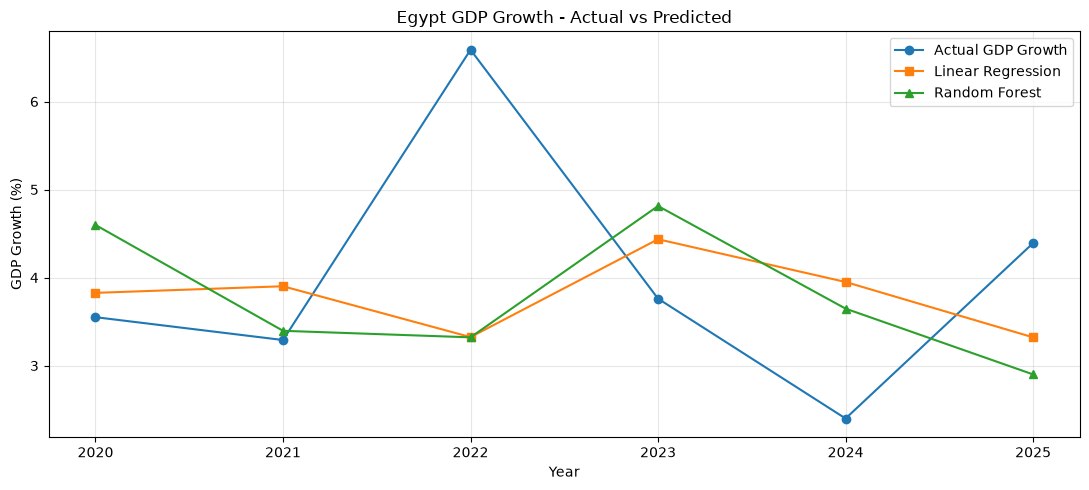

In [93]:
# Prediction Visualization — Egypt Actual vs Forecast
egypt_predictions = test[
    test['Country Name'] == 'Egypt, Arab Rep.'
][['Year', 'GDP_Growth']].copy()

egypt_predictions['Linear_Regression'] = y_pred[
    (test['Country Name'] == 'Egypt, Arab Rep.').to_numpy()
]

egypt_predictions['Random_Forest'] = rf_pred[
    (test['Country Name'] == 'Egypt, Arab Rep.').to_numpy()
]

plt.figure(figsize=(11, 5))

plt.plot(
    egypt_predictions['Year'],
    egypt_predictions['GDP_Growth'],
    marker='o',
    label='Actual GDP Growth'
)

plt.plot(
    egypt_predictions['Year'],
    egypt_predictions['Linear_Regression'],
    marker='s',
    label='Linear Regression'
)

plt.plot(
    egypt_predictions['Year'],
    egypt_predictions['Random_Forest'],
    marker='^',
    label='Random Forest'
)

plt.title('Egypt GDP Growth - Actual vs Predicted')
plt.xlabel('Year')
plt.ylabel('GDP Growth (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Country Model Evaluation — Egypt MAE

قياس متوسط خطأ كل نموذج لمصر فقط.

In [94]:
# Country Model Evaluation — Egypt MAE
from sklearn.metrics import mean_absolute_error

egypt_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [
        mean_absolute_error(
            egypt_predictions['GDP_Growth'],
            egypt_predictions['Linear_Regression']
        ),
        mean_absolute_error(
            egypt_predictions['GDP_Growth'],
            egypt_predictions['Random_Forest']
        )
    ]
})

egypt_results = egypt_results.sort_values('MAE')

egypt_results.round(4)


,Model,MAE
0,Linear Regression,1.2413
1,Random Forest,1.3686


### Prediction Explorer — Country & Year Lookup

جدول قابل للتصفية لعرض توقعات دولة وسنة تاريخية محددة.

In [95]:
# Prediction Explorer — Country & Year Lookup
prediction_system = test[
    ['Country Name', 'Year', 'GDP_Growth']
].copy()

prediction_system['Linear_Regression'] = y_pred
prediction_system['Random_Forest'] = rf_pred

country_name = 'Egypt, Arab Rep.'
year = 2025

result = prediction_system[
    (prediction_system['Country Name'] == country_name) &
    (prediction_system['Year'] == year)
]

result.round(3)


,Country Name,Year,GDP_Growth,Linear_Regression,Random_Forest
179,"Egypt, Arab Rep.",2025,4.392,3.321,2.9


### Forecast Readiness — Recent Egypt Indicators

مراجعة النمو والتضخم والبطالة لمصر لعامَي 2024 و2025.

In [96]:
# Forecast Readiness — Recent Egypt Indicators
egypt_latest = df_features[
    (df_features['Country Name'] == 'Egypt, Arab Rep.') &
    (df_features['Year'].isin([2024, 2025]))
][
    ['Year', 'GDP_Growth', 'Inflation', 'Unemployment']
]

egypt_latest


,Year,GDP_Growth,Inflation,Unemployment
178,2024,2.399169,28.270590,6.817
179,2025,4.392011,14.073514,6.781


### Forecast Feature Builder — Egypt 2026

حساب قيم Features التنبؤ بسنة 2026 باستخدام آخر سنوات سابقة متاحة.

In [97]:
# Forecast Feature Builder — Egypt 2026
egypt_history = df_features[
    df_features['Country Name'] == 'Egypt, Arab Rep.'
].sort_values('Year')

last_3_years = egypt_history[
    egypt_history['Year'].isin([2023, 2024, 2025])
].sort_values('Year')

assert last_3_years['Year'].tolist() == [2023, 2024, 2025]

X_2026 = pd.DataFrame([{
    'GDP_Lag1': last_3_years.iloc[-1]['GDP_Growth'],

    'GDP_Rolling3': last_3_years['GDP_Growth'].mean(),

    'Inflation_Lag1': last_3_years.iloc[-1]['Inflation'],

    'Unemployment_Change': (
        last_3_years.iloc[-1]['Unemployment']
        - last_3_years.iloc[-2]['Unemployment']
    )
}])

X_2026 = X_2026[features]

X_2026.round(4)


,GDP_Lag1,GDP_Rolling3,Inflation_Lag1,Unemployment_Change
0,4.392,3.5172,14.0735,-0.036


---

## 12 · Forecasting Engine — GDP Growth 2026

تدريب النماذج على البيانات المتاحة وإنتاج توقعات تجريبية.

### Final Model Training — Egypt 2026 Forecast

إعادة تدريب النموذجين على السجل المتاح ثم توقع GDP Growth لمصر في 2026 وحفظ النتيجة.

In [ ]:
# Production-Style Retraining — Egypt 2026 Forecast
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# ========================================
# 1. Features
# ========================================

features = [
    'GDP_Lag1',
    'GDP_Rolling3',
    'Inflation_Lag1',
    'Unemployment_Change'
]

# ========================================
# 2. Prepare Training Data
# ========================================

training_data = df_features[
    ['Country Name', 'Year'] + features + ['GDP_Growth']
].dropna().copy()

training_data = training_data[
    training_data['Year'] <= 2025
]

X = training_data[features]
y = training_data['GDP_Growth']

# ========================================
# 3. Train Models
# ========================================

linear_model_final = LinearRegression()

forest_model_final = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

linear_model_final.fit(X, y)
forest_model_final.fit(X, y)

# ========================================
# 4. Prepare Egypt 2026 Features
# ========================================

egypt = df_features[
    df_features['Country Name'] == 'Egypt, Arab Rep.'
].sort_values('Year')

history = egypt[
    egypt['Year'].isin([2023, 2024, 2025])
].sort_values('Year')

assert history['Year'].tolist() == [2023, 2024, 2025], \
    "Missing historical years"

required = ['GDP_Growth', 'Inflation', 'Unemployment']

assert history[required].notna().all().all(), \
    "Missing historical indicator values"

X_2026 = pd.DataFrame([{
    'GDP_Lag1': history.iloc[-1]['GDP_Growth'],

    'GDP_Rolling3': history['GDP_Growth'].mean(),

    'Inflation_Lag1': history.iloc[-1]['Inflation'],

    'Unemployment_Change': (
        history.iloc[-1]['Unemployment']
        - history.iloc[-2]['Unemployment']
    )
}])[features]

# ========================================
# 5. Predict GDP Growth 2026
# ========================================

linear_prediction = linear_model_final.predict(X_2026)[0]
forest_prediction = forest_model_final.predict(X_2026)[0]

# ========================================
# 6. Final Results
# ========================================

forecast_2026 = pd.DataFrame({
    'Country': ['Egypt'],
    'Year': [2026],
    'Linear Regression (%)': [linear_prediction],
    'Random Forest (%)': [forest_prediction]
})

print("EGYPT GDP GROWTH FORECAST 2026")
print("=" * 40)

display(forecast_2026.round(3))

# ========================================
# 7. Save Predictions
# ========================================

forecast_2026.to_csv(
    DATA_DIR / 'egypt_gdp_forecast_2026.csv',
    index=False
)

print("Forecast saved successfully!")


### Global Forecast Engine — 2026 / All Countries

إنشاء توقعات 2026 للدول ذات البيانات الكافية وحفظ أسباب استبعاد الدول الأخرى.

In [ ]:
# Global Forecast Engine — 2026 / All Countries
import pandas as pd
import matplotlib.pyplot as plt

# ========================================
# GLOBAL GDP FORECAST ENGINE - 2026
# ========================================

forecasts = []
skipped_countries = []

for country, data in df_features.groupby('Country Name'):

    history = data[
        data['Year'].isin([2023, 2024, 2025])
    ].sort_values('Year')

    if history['Year'].tolist() != [2023, 2024, 2025]:
        skipped_countries.append((country, 'Missing years'))
        continue

    required = ['GDP_Growth', 'Inflation', 'Unemployment']

    if history[required].isna().any().any():
        skipped_countries.append((country, 'Missing indicators'))
        continue

    # Prepare 2026 features
    X_future = pd.DataFrame([{
        'GDP_Lag1': history.iloc[-1]['GDP_Growth'],

        'GDP_Rolling3': history['GDP_Growth'].mean(),

        'Inflation_Lag1': history.iloc[-1]['Inflation'],

        'Unemployment_Change': (
            history.iloc[-1]['Unemployment']
            - history.iloc[-2]['Unemployment']
        )
    }])[features]

    # Generate predictions
    lr_prediction = linear_model_final.predict(X_future)[0]
    rf_prediction = forest_model_final.predict(X_future)[0]

    forecasts.append({
        'Country': country,
        'Year': 2026,
        'GDP_2025': history.iloc[-1]['GDP_Growth'],
        'Linear_Regression': lr_prediction,
        'Random_Forest': rf_prediction
    })

# ========================================
# RESULTS
# ========================================

global_forecast = pd.DataFrame(forecasts)

global_forecast = global_forecast.sort_values(
    'Random_Forest',
    ascending=False
).reset_index(drop=True)

print("GLOBAL ECONOMIC DATA ANALYSIS & FORECASTING")
print("=" * 45)
print("Forecast Year: 2026")
print("Countries Forecasted:", len(global_forecast))
print("Countries Skipped:", len(skipped_countries))

display(global_forecast.round(3))

if skipped_countries:
    print("Skipped Countries:")
    display(pd.DataFrame(
        skipped_countries,
        columns=['Country', 'Reason']
    ))

# ========================================
# VISUALIZATION
# ========================================

plt.figure(figsize=(12, 9))

plt.barh(
    global_forecast['Country'],
    global_forecast['Random_Forest']
)

plt.gca().invert_yaxis()

plt.axvline(0, color='gray', linewidth=1)

plt.title('Global GDP Growth Forecast - 2026')
plt.xlabel('Predicted GDP Growth (%)')
plt.ylabel('Country')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# ========================================
# SAVE RESULTS
# ========================================

global_forecast.to_csv(
    DATA_DIR / 'global_gdp_forecast_2026.csv',
    index=False
)

print("Global Forecast Saved Successfully!")


---

## 13 · Data Export & Interactive Dashboard

إخراج ملفات العرض وإنشاء تطبيق Streamlit متعدد الصفحات.

### Data Export — Dashboard & Model Artifacts

تصدير ملفات CSV المطلوبة لتشغيل الـDashboard وتقارير تقييم النماذج.

In [ ]:
# Data Export — Dashboard and Model Reports
# Export the calculated tables into the processed-data folder for the web app.
from pathlib import Path
DATA_DIR.mkdir(parents=True, exist_ok=True)

export_tables = {
    'economic_clean.csv': df_clean,
    'economic_pivot.csv': economic_pivot,
    'economic_features.csv': df_features,
    'economic_model_dataset.csv': df_model,
    'model_comparison.csv': final_comparison,
    'validation_results.csv': all_results,
    'global_gdp_forecast_2026.csv': global_forecast,
}

quality_report = pd.DataFrame({
    'Column': ['GDP_Growth', 'Inflation', 'Unemployment'],
    'Missing Values': [int(economic_pivot[c].isna().sum()) for c in ['GDP_Growth', 'Inflation', 'Unemployment']],
    'Non-Missing Values': [int(economic_pivot[c].notna().sum()) for c in ['GDP_Growth', 'Inflation', 'Unemployment']],
})
export_tables['data_quality_report.csv'] = quality_report
export_tables['excluded_countries.csv'] = pd.DataFrame(
    skipped_countries, columns=['Country', 'Reason']
)

for name, frame in export_tables.items():
    frame.to_csv(DATA_DIR / name, index=False)
    print(f'Saved: data/processed/{name}')


### Interactive Dashboard — Application Entry Point

تطبيق Streamlit مستقل في ملف `app.py`، وبيقرأ ملفات CSV اللي اتصدّرت من خطوة **Data Export**.
فصل الواجهة عن كود التحليل بيخلّي صيانة المشروع والنشر أسهل.


In [ ]:
# Dashboard — Confirm App File Is Present
app_path = PROJECT_ROOT / 'app.py'
if not app_path.exists():
    raise FileNotFoundError('app.py is missing from the project root.')
print('Dashboard:', app_path)
print('To run: python -m streamlit run app.py')


### Deployment Requirements — Environment Check

ملفا `requirements.txt` و`.streamlit/config.toml` متضمنان داخل المشروع، وبيحدّدوا المكتبات وإعدادات الواجهة.


In [ ]:
# Deployment — Verify Requirements
required_project_files = [
    PROJECT_ROOT / 'requirements.txt',
    PROJECT_ROOT / '.streamlit' / 'config.toml',
    PROJECT_ROOT / 'scripts' / 'build_data.py',
]
for item in required_project_files:
    print(('OK' if item.exists() else 'MISSING'), item.relative_to(PROJECT_ROOT))


---
## Run the Project

**Option A — Data analysis in Jupyter**

1. Put `API_Download_DS2_EN_csv_v2_146823_LIST.csv` inside `data/raw/`.
2. Open `notebooks/Economic_Analysis.ipynb` and run the cells in order.
3. Run the final **Data Export** cell to update the dashboard inputs.

**Option B — Prepare data and launch the web dashboard**

From the **repository root**, run:

```bash
python -m pip install -r requirements.txt
python scripts/build_data.py
python -m streamlit run app.py
```

Open the local Streamlit URL shown in the terminal, usually `http://localhost:8501`.

**Interpretation:** Annual GDP growth is measured in percent; prediction errors MAE/RMSE are percentage points. The 2026 numbers are experimental model estimates, not official projections. Model performance varies by country and time, and 2025 source data may be revised.
